# 04 · Asignación de capital con RL (Bloque 3)

Un agente Q-learning tabular aprende una política legible *fase → cartera*. Validación
walk-forward con **test fuera de muestra**. Reporte honesto del resultado.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))

import matplotlib.pyplot as plt

from athenai.config import load_config
from athenai.data.build import load_processed
from athenai.evaluation import metrics
from athenai.pipeline import run_allocation, run_regimes
from athenai.regimes.fuzzy import REGIMES
from athenai.viz import style as S

S.set_style()
cfg = load_config()
proc = load_processed(cfg)
reg = run_regimes(cfg, proc)
alloc = run_allocation(cfg, proc, reg["dominant"])

C:\Users\ferju\AppData\Local\Programs\Python\Python310\lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] El sistema no puede encontrar el archivo especificado
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\ferju\AppData\Local\Programs\Python\Python310\lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
  File "C:\Users\ferju\AppData\Local\Programs\Python\Python310\lib\subprocess.py", line 501, in run
    with Popen(*popenargs, **kwargs) as process:
  File "C:\Users\ferju\AppData\Local\Programs\Python\Python310\lib\subprocess.py", line 969, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Users\ferju\AppData\Local\Programs\Python\Python

## Política aprendida (fase dominante → cartera)

In [2]:
for r in REGIMES:
    print(f"{r:9} -> cartera {int(alloc['policy'].loc[r])} ({REGIMES[int(alloc['policy'].loc[r])]})")

alcista   -> cartera 2 (lateral)
bajista   -> cartera 1 (bajista)
lateral   -> cartera 2 (lateral)
crisis    -> cartera 0 (alcista)


## Resultados en el periodo de TEST (fuera de muestra)

In [3]:
alloc["results"]["test"].round(4)

,CAGR,vol_anual,Sharpe,Sortino,max_drawdown,Calmar,pct_periodos_positivos,turnover
rl,0.0071,0.0235,0.3136,0.6277,-0.0233,0.3070,0.5000,0.4222
difusa_sin_rl,-0.0566,0.0351,-1.6429,-2.7527,-0.0537,-1.0554,0.2500,0.4889
equiponderado,0.0288,0.0097,2.9476,4.6249,-0.0046,6.2015,0.8333,0.0000
mejor_algo,0.1518,0.1197,1.2430,0.9079,-0.0690,2.2000,0.6667,0.0000
benchmark,0.0679,0.0376,1.7691,6.5637,-0.0154,4.4028,0.6667,NaN


## Curva de capital en TEST: estrategia vs benchmark vs equiponderado

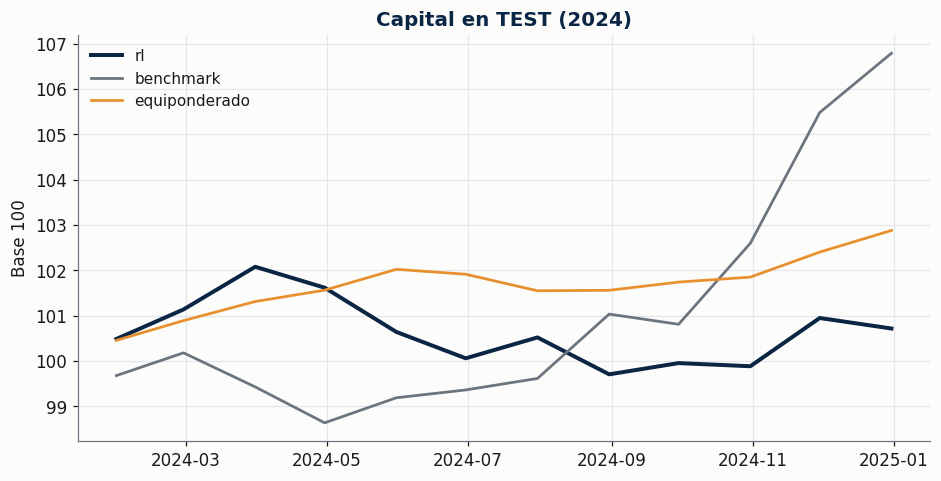

In [4]:
splits = alloc["splits"]
lo, hi = splits["val_end"], splits["test_end"]


def seg(s):
    return s[(s.index > lo) & (s.index <= hi)]


fig, ax = plt.subplots(figsize=(10, 4.8))
for key, ck in [("rl", "estrategia"), ("benchmark", "benchmark"), ("equiponderado", "equiponderado")]:
    eq = metrics.equity_curve(seg(alloc["series_net"][key]))
    ax.plot(eq.index, eq, label=key, color=S.SERIES_COLORS[ck],
            lw=2.6 if key == "rl" else 1.8)
ax.set_title("Capital en TEST (2024)")
ax.set_ylabel("Base 100")
ax.legend()
plt.show()

## Conclusión honesta

La estrategia RL **no bate al benchmark fuera de muestra**: aprende un comportamiento defensivo
que protege capital (drawdown bajo) pero se pierde parte de las subidas. Con ~30 observaciones
mensuales de entrenamiento y 4 estados, el riesgo de sobreajuste es real, y el equiponderado
simple resulta un rival muy fuerte. El resultado se reporta sin maquillar.

El experimento cuántico (Bloque 4) está en `scripts/run_quantum.py` y su figura en
`docs/img/quantum_qaoa.png`.